# Uncertainty Aware Agentic Refinement

This notebook reviews predictions, judges scores and uncertainty scores, and then based on budget refines those selected predictions.
This includes:

1. **Judges score ** - 10 specialists judges evaluate different aspects of the predicted graph.
2. **Coefficient of Variations** - The uncertainty metric most aligned with graph extraction errors, refinement selection is based on this rank
3. **Planner** - LangGraph agent focusing on the analysis of the scores
4. **Refinere** - LangGraph agent performing the refinement
5. **Verifier** - LangGraph agent deciding if the refined graph is good enough or if additional agentic loop iterations are needed

**Input**: Predictions jsonl file, judges scores with uncertainty values. `

**Output**: Refined predictions saved to a new jsonl

## 1. Setup and Imports

In [1]:
!pip install -U openai langgraph langchain langchain-openai tiktoken


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.3/157.3 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.1/102.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.3/84.3 kB 3.0 MB/s eta 0:00:00
  Attempting uninstall: openai
    Found existing installation: openai 2.8.1
    Uninstalling openai-2.8.1:
      Successfully uninstalled openai-2.8.1
  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.0.3
    Uninstalling langgraph-1.0.3:
      Successfully uninstalled langgraph-1.0.3
  Attempting uninstall: langchain
    Found existing installation: langchain 1.1.0
    Uninstalling langchain-1.1.0:
      Successfully uninstalled langchain-1.1.0


In [2]:
import os
import json
import datetime
from typing import TypedDict, Dict, Any, List, Optional

from dataclasses import dataclass, asdict

from openai import OpenAI

from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver


In [4]:
from google.colab import userdata
from google.colab import drive

drive.mount('/content/drive')

OPENAI_API_KEY = userdata.get('OpenAIService')

if "OPENAI_API_KEY" not in os.environ:
    os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

client = OpenAI()


Mounted at /content/drive


## 2. Setup input and output paths

In [15]:
# Input paths (your Drive layout)
PREDICTIONS_PATH = "/content/drive/MyDrive/multiJudgePredictions-full/predictions.jsonl"
JUDGE_SUMMARY_PATH = "/content/drive/MyDrive/multiJudgeScores_non_gold/judge_scores_summary_20251104_201357_fixed.csv"
JUDGE_UNCERTAINTY_PATH = "/content/drive/MyDrive/ACLing/multi_judge_scores/judge_scores_with_uncertainties.csv"

# Output paths for refined graphs (you can change folder/name if you want)
REFINED_ONLY_PATH = "/content/drive/MyDrive/multiJudgeRefinements/refined_top14_cv.jsonl"
FULL_MERGED_PATH = "/content/drive/MyDrive/multiJudgeRefinements/predictions_with_refinements_top14_cv.jsonl"

os.makedirs(os.path.dirname(REFINED_ONLY_PATH), exist_ok=True)

# Models for each agent
PLANNER_MODEL = "gpt-4.1-mini"
REFINER_MODEL = "gpt-5"
EVALUATOR_MODEL = "gpt-4.1-mini"

# Agent loop configuration
N_TOP_CV = 14
MAX_ITERATIONS_PER_SAMPLE = 3


## 3. Load Predictions

In [16]:
import pandas as pd

def load_predictions(path: str) -> pd.DataFrame:
    """
    Load predictions.jsonl and extract:
      - sample_id (matches sample_id in judge CSVs)
      - contract_id, clause_id
      - clause title and text
      - original extraction instruction
      - prediction graph JSON
    """
    records = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            row = json.loads(line)
            prompt_obj = json.loads(row["prompt"])
            clause = prompt_obj["input"]["clause"]

            records.append({
                "index": row["index"],
                "sample_id": row["id"],  # <-- this matches sample_id in the CSVs
                "contract_id": row["contract_id"],
                "clause_id": row["clause_id"],
                "clause_title": clause.get("title", ""),
                "clause_text": clause.get("text", ""),
                "extraction_instruction": prompt_obj["instruction"],
                "prompt_raw": row["prompt"],
                "gold_minigraph_raw": row["gold_minigraph"],
                "prediction_text_raw": row["prediction_text"],
                "prediction_json": row["prediction_json"],
            })
    return pd.DataFrame.from_records(records)


def load_judge_uncertainties(path: str) -> pd.DataFrame:
    """
    Load per-sample multi-judge metrics and uncertainty scores.
    """
    return pd.read_csv(path)


def load_judge_summary(path: str) -> pd.DataFrame:
    """
    Optional: aggregated judge scores (without uncertainty). Not strictly needed
    for the agentic loop, but loaded for completeness.
    """
    return pd.read_csv(path)


pred_df = load_predictions(PREDICTIONS_PATH)
uncert_df = load_judge_uncertainties(JUDGE_UNCERTAINTY_PATH)
summary_df = load_judge_summary(JUDGE_SUMMARY_PATH)

print("Predictions:", pred_df.shape)
print("Judge uncertainty:", uncert_df.shape)
print("Judge summary:", summary_df.shape)

# Sanity check: sample_id in CSVs matches id in predictions.jsonl
assert set(pred_df["sample_id"]) == set(uncert_df["sample_id"]), "sample_id / id mismatch!"
print("sample_id ↔ id mapping is consistent across files.")

Predictions: (150, 11)
Judge uncertainty: (150, 35)
Judge summary: (150, 20)
sample_id ↔ id mapping is consistent across files.


## 4. Load uncertainty and judges scores

In [17]:
# Merge predictions with judge uncertainty metrics on sample_id
merged_df = uncert_df.merge(
    pred_df,
    on="sample_id",
    how="inner",
    suffixes=("", "_pred"),
)

print("Merged shape:", merged_df.shape)

# Quick check – contract_id / clause_id agree between sources
assert (merged_df["contract_id"] == merged_df["contract_id_pred"]).all()
assert (merged_df["clause_id"] == merged_df["clause_id_pred"]).all()

# Keep columns we need; drop the duplicate *_pred versions
merged_df = merged_df.drop(columns=["contract_id_pred", "clause_id_pred"])

# Select the 14 most uncertain samples by CV (descending)
uncertain_df = (
    merged_df
    .sort_values("cv", ascending=False)
    .head(N_TOP_CV)
    .reset_index(drop=True)
)

print(f"Selected {len(uncertain_df)} samples for refinement (top {N_TOP_CV} by CV).")
display(
    uncertain_df[["sample_id", "contract_id", "clause_id", "cv", "hybrid_score", "has_error"]]
)


Merged shape: (150, 45)
Selected 14 samples for refinement (top 14 by CV).


,sample_id,contract_id,clause_id,cv,hybrid_score,has_error
0,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,15.5.2.4,2.236067,0.000000,1
1,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,25,0.627758,0.410371,1
2,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,14,0.580051,0.532128,1
3,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,38,0.544368,0.598870,1
4,NEOMEDIATECHNOLOGIESINC_12_15_2005-EX-16.1-DIS...,NEOMEDIATECHNOLOGIESINC_12_15_2005-EX-16.1-DIS...,20.5,0.520405,0.581666,1
5,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,(o,0.487453,0.661665,1
6,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,17,0.469410,0.641967,1
7,NEOMEDIATECHNOLOGIESINC_12_15_2005-EX-16.1-DIS...,NEOMEDIATECHNOLOGIESINC_12_15_2005-EX-16.1-DIS...,10,0.419866,0.813639,1
8,NEOMEDIATECHNOLOGIESINC_12_15_2005-EX-16.1-DIS...,NEOMEDIATECHNOLOGIESINC_12_15_2005-EX-16.1-DIS...,(d,0.408126,0.901904,1
9,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRA...,(k,0.407469,0.598097,1


In [18]:
# Core quality metrics per sample
CORE_SCORE_COLS = [
    "exact_match_score",
    "structural_f1_score",
    "semantic_similarity_score",
    "openai_issues_score",
    "gemini_changes_score",
    "hybrid_score",
    "parse_success_score",
    "completeness_score",
    "graph_edit_distance_score",
]

# Uncertainty / risk metrics per sample
UNCERTAINTY_COLS = [
    "cv",
    "entropy",
    "range",
    "pairwise",
    "margin",
    "iqr",
    "variance",
    "std",
    "n_judges_used",
    "mean_risk",
    "p_error_hat_mean_risk",
    "p_error_hat_calibrated",
    "p_error_hat_final",
    "has_error",
]


## 5. Setup agents

In [27]:
import re

class AgentState(TypedDict, total=False):
    # Static sample metadata
    sample_id: str
    contract_id: str
    clause_id: str
    clause_title: str
    clause_text: str
    extraction_instruction: str

    # Graphs
    baseline_graph: Dict[str, Any]
    best_graph: Dict[str, Any]
    candidate_graph: Dict[str, Any]

    # Metrics
    judge_scores: Dict[str, float]
    uncertainty_scores: Dict[str, float]

    # Agent loop artifacts
    planner_output: Dict[str, Any]
    refinement_instructions: str
    evaluator_output: Dict[str, Any]
    accepted: bool
    iterations: int
    max_iterations: int


def extract_json_object(text: str) -> Dict[str, Any]:
    """
    Extract the first JSON object from an LLM response and parse it.
    Assumes the response contains a single top-level {...}.
    """
    match = re.search(r"\{.*\}", text, flags=re.DOTALL)
    if not match:
        raise ValueError(f"No JSON object found in:\n{text[:500]}")
    json_str = match.group(0)
    return json.loads(json_str)

In [20]:
def build_initial_state(rec: Dict[str, Any], max_iterations: int = MAX_ITERATIONS_PER_SAMPLE) -> AgentState:
    judge_scores = {col: float(rec[col]) for col in CORE_SCORE_COLS if col in rec}
    uncertainty_scores = {col: float(rec[col]) for col in UNCERTAINTY_COLS if col in rec}

    state: AgentState = {
        "sample_id": rec["sample_id"],
        "contract_id": rec["contract_id"],
        "clause_id": rec["clause_id"],
        "clause_title": rec.get("clause_title", ""),
        "clause_text": rec.get("clause_text", ""),
        "extraction_instruction": rec.get("extraction_instruction", ""),
        "baseline_graph": rec["prediction_json"],
        "best_graph": rec["prediction_json"],
        "judge_scores": judge_scores,
        "uncertainty_scores": uncertainty_scores,
        "iterations": 0,
        "max_iterations": max_iterations,
        "accepted": False,
    }
    return state


In [29]:
PLANNER_SYSTEM_PROMPT = """
You are the Planning Agent in a multi-agent legal graph refinement system.

You see a single contract clause, an existing legal knowledge graph extracted
for that clause, and aggregated multi-judge quality scores plus uncertainty
estimates.

Your job is to analyze likely problems in the existing graph and produce a
targeted plan for refinement.
""".strip()


def planner_node(state: AgentState) -> AgentState:
    judge_scores = state.get("judge_scores", {})
    uncertainty_scores = state.get("uncertainty_scores", {})

    metrics_lines = "\n".join(
        f"- {k}: {v:.4f}" for k, v in judge_scores.items()
    )
    uncertainty_lines = "\n".join(
        f"- {k}: {v:.4f}" for k, v in uncertainty_scores.items()
    )

    baseline_graph_json_str = json.dumps(state["baseline_graph"], indent=2, ensure_ascii=False)

    user_content = f"""
[Clause]
- Contract ID: {state['contract_id']}
- Clause ID: {state['clause_id']} ({state['clause_title']})

Clause text:
{state['clause_text']}

[Current graph JSON]
{baseline_graph_json_str}

[Aggregated judge scores on this graph]
{metrics_lines}

[Uncertainty estimates]
{uncertainty_lines}

Your task:

1. Summarize the most probable issues with this graph (e.g. missing key nodes,
   incorrect edge types, ontology violations, spurious nodes, etc.).
2. Propose a focused refinement strategy specifying which nodes/edges to add,
   modify, or remove.
3. Convert this strategy into a concrete instruction string that a downstream
   Refinement Agent will follow to rewrite the graph.

Respond ONLY with a JSON object of the form:

{{
  "short_summary": "...",
  "main_issues": ["...", "..."],
  "refinement_instructions": "..."
}}
""".strip()

    response = client.chat.completions.create(
        model=PLANNER_MODEL,
        messages=[
            {"role": "system", "content": PLANNER_SYSTEM_PROMPT},
            {"role": "user", "content": user_content},
        ],
        temperature=1,
    )

    content = response.choices[0].message.content
    plan = extract_json_object(content)

    state["planner_output"] = plan
    state["refinement_instructions"] = plan.get("refinement_instructions", "")
    return state


In [30]:
REFINER_SYSTEM_PROMPT = """
You are the Refinement Agent in a multi-agent legal graph extraction system.

You receive:
- The original extraction instructions used to produce the graph
- The clause text
- The current graph JSON
- Targeted refinement instructions from a planner

You must return an improved graph that better reflects the clause while obeying
the ontology and keeping the JSON schema exactly the same.
""".strip()


def refiner_node(state: AgentState) -> AgentState:
    base_instr = state.get("extraction_instruction", "")
    refinement_instructions = state.get("refinement_instructions", "")
    clause_text = state.get("clause_text", "")
    baseline_graph_json_str = json.dumps(state["baseline_graph"], indent=2, ensure_ascii=False)

    user_content = f"""
[Original extraction instructions]
{base_instr}

[Clause]
- Contract ID: {state['contract_id']}
- Clause ID: {state['clause_id']} ({state['clause_title']})

Clause text:
{clause_text}

[Current graph JSON]
{baseline_graph_json_str}

[Refinement instructions from planner]
{refinement_instructions}

Requirements:

- Return ONLY JSON, no markdown or explanation.
- The top-level structure MUST be:
  {{
    "contract_id": "...",
    "nodes": [...],
    "edges": [...]
  }}
- The "contract_id" must remain exactly "{state['contract_id']}".
- Preserve existing node/edge identifiers where they remain semantically valid.
- Only add/remove/change nodes/edges as needed to implement the refinement
  instructions and better reflect the clause.
""".strip()

    response = client.chat.completions.create(
        model=REFINER_MODEL,
        messages=[
            {"role": "system", "content": REFINER_SYSTEM_PROMPT},
            {"role": "user", "content": user_content},
        ],
        temperature=1,
    )

    content = response.choices[0].message.content
    candidate_graph = extract_json_object(content)

    state["candidate_graph"] = candidate_graph
    return state


In [31]:
EVALUATOR_SYSTEM_PROMPT = """
You are the Evaluation Agent in a multi-agent legal graph refinement system.

You see:
- The clause text
- The original graph
- A candidate refined graph
- Aggregated judge scores and uncertainty metrics on the ORIGINAL graph

You must decide whether the candidate refined graph is strictly better than the
original in terms of:
- Structural faithfulness to the clause
- Semantic coverage (capturing key legal entities and relations)
- Ontology compliance and graph cleanliness
""".strip()


def evaluator_node(state: AgentState) -> AgentState:
    # Increment iteration count
    state["iterations"] = int(state.get("iterations", 0)) + 1

    baseline_graph_json_str = json.dumps(state["baseline_graph"], indent=2, ensure_ascii=False)
    candidate_graph_json_str = json.dumps(state["candidate_graph"], indent=2, ensure_ascii=False)

    judge_scores = state.get("judge_scores", {})
    uncertainty_scores = state.get("uncertainty_scores", {})

    metrics_lines = "\n".join(
        f"- {k}: {v:.4f}" for k, v in judge_scores.items()
    )
    uncertainty_lines = "\n".join(
        f"- {k}: {v:.4f}" for k, v in uncertainty_scores.items()
    )

    user_content = f"""
[Clause]
- Contract ID: {state['contract_id']}
- Clause ID: {state['clause_id']} ({state['clause_title']})

Clause text:
{state['clause_text']}

[Original graph JSON]
{baseline_graph_json_str}

[Candidate refined graph JSON]
{candidate_graph_json_str}

[Aggregated judge scores on ORIGINAL graph]
{metrics_lines}

[Uncertainty metrics on ORIGINAL graph]
{uncertainty_lines}

Your task:

1. Compare the candidate graph to the clause and the original graph.
2. Decide whether the candidate is strictly better, worse, or about the same.
3. Be conservative: accept only if clearly better overall.

Respond ONLY with a JSON object of the form:

{{
  "decision": "accept" | "reject" | "uncertain",
  "justification": "One or two concise paragraphs explaining your decision.",
  "estimated_quality_delta": {{
    "structural_f1": float,  # positive means improvement, negative means worse
    "semantic_similarity": float
  }}
}}
""".strip()

    response = client.chat.completions.create(
        model=EVALUATOR_MODEL,
        messages=[
            {"role": "system", "content": EVALUATOR_SYSTEM_PROMPT},
            {"role": "user", "content": user_content},
        ],
        temperature=0.2,
    )

    content = response.choices[0].message.content
    eval_json = extract_json_object(content)

    state["evaluator_output"] = eval_json
    decision = str(eval_json.get("decision", "uncertain")).lower()

    accepted = decision == "accept"
    state["accepted"] = accepted

    # Initialize best_graph if this is the first iteration
    if "best_graph" not in state:
        state["best_graph"] = state["baseline_graph"]

    # Update best_graph if accepted
    if accepted:
        state["best_graph"] = state["candidate_graph"]

    return state


def route_after_evaluator(state: AgentState) -> str:
    """
    Decide whether to loop again or stop.

    Returns:
      - "continue" to go back to planner
      - "end" to terminate
    """
    if state.get("accepted"):
        return "end"
    if int(state.get("iterations", 0)) >= int(state.get("max_iterations", 1)):
        return "end"
    return "continue"


## 6. Agentic Refinement Loop

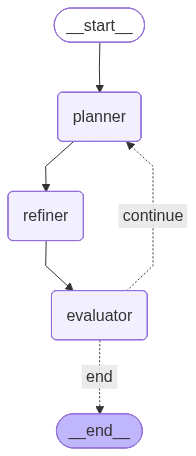

In [32]:
from langgraph.graph import START

workflow = StateGraph(AgentState)

workflow.add_node("planner", planner_node)
workflow.add_node("refiner", refiner_node)
workflow.add_node("evaluator", evaluator_node)

# Entry and normal edges
workflow.add_edge(START, "planner")
workflow.add_edge("planner", "refiner")
workflow.add_edge("refiner", "evaluator")

# Conditional edge from evaluator back to planner or to END
workflow.add_conditional_edges(
    "evaluator",
    route_after_evaluator,
    {
        "continue": "planner",
        "end": END,
    },
)

graph = workflow.compile()
graph  # Display graph object in Colab

## 7. Perform selective refinement

In [33]:
uncertain_records = uncertain_df.to_dict(orient="records")

results = []

for i, rec in enumerate(uncertain_records, start=1):
    print("=" * 80)
    print(f"Sample {i}/{len(uncertain_records)}")
    print(f"sample_id   : {rec['sample_id']}")
    print(f"contract_id : {rec['contract_id']}")
    print(f"clause_id   : {rec['clause_id']}")
    print(f"cv          : {rec['cv']:.4f}")
    print("-" * 80)

    state = build_initial_state(rec, max_iterations=MAX_ITERATIONS_PER_SAMPLE)

    try:
        final_state = graph.invoke(state)

        accepted = bool(final_state.get("accepted", False))
        iterations = int(final_state.get("iterations", 0))
        best_graph = final_state.get("best_graph", state["baseline_graph"])

        results.append({
            "index": int(rec["index"]),
            "sample_id": rec["sample_id"],
            "contract_id": rec["contract_id"],
            "clause_id": rec["clause_id"],
            "prompt_raw": rec["prompt_raw"],
            "gold_minigraph_raw": rec["gold_minigraph_raw"],
            "baseline_graph": state["baseline_graph"],
            "final_graph": best_graph,
            "accepted": accepted,
            "iterations": iterations,
            "planner_output": final_state.get("planner_output"),
            "evaluator_output": final_state.get("evaluator_output"),
        })

        print(f"Decision: {'ACCEPTED' if accepted else 'NOT ACCEPTED'} after {iterations} iteration(s).")

    except Exception as e:
        print(f"Error refining sample {rec['sample_id']}: {e}")

        # Fallback: keep baseline graph
        results.append({
            "index": int(rec["index"]),
            "sample_id": rec["sample_id"],
            "contract_id": rec["contract_id"],
            "clause_id": rec["clause_id"],
            "prompt_raw": rec["prompt_raw"],
            "gold_minigraph_raw": rec["gold_minigraph_raw"],
            "baseline_graph": state["baseline_graph"],
            "final_graph": state["baseline_graph"],
            "accepted": False,
            "iterations": 0,
            "planner_output": None,
            "evaluator_output": {"decision": "error", "error_message": str(e)},
        })


Sample 1/14
sample_id   : INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE AGREEMENT/INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE_AGREEMENT_15.5.2.4
contract_id : INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE AGREEMENT
clause_id   : 15.5.2.4
cv          : 2.2361
--------------------------------------------------------------------------------
Decision: ACCEPTED after 1 iteration(s).
Sample 2/14
sample_id   : INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE AGREEMENT/INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE_AGREEMENT_25
contract_id : INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE AGREEMENT
clause_id   : 25
cv          : 0.6278
--------------------------------------------------------------------------------
Decision: ACCEPTED after 1 iteration(s).
Sample 3/14
sample_id   : INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE AGREEMENT/INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE_AGREEMENT_14
contract_id : INTERNATIONALFASTFOODCORP_04_04_199

In [34]:
refined_only_path = REFINED_ONLY_PATH

with open(refined_only_path, "w", encoding="utf-8") as f:
    for r in results:
        # Use final_graph as the new prediction
        final_graph = r["final_graph"]

        # Optional: capture evaluator justification as parse note
        parse_note = None
        if isinstance(r.get("evaluator_output"), dict):
            parse_note = r["evaluator_output"].get("justification")

        out_row = {
            "index": r["index"],
            "id": r["sample_id"],
            "contract_id": r["contract_id"],
            "clause_id": r["clause_id"],
            "prompt": r["prompt_raw"],
            "gold_minigraph": r["gold_minigraph_raw"],
            "prediction_text": json.dumps(final_graph, ensure_ascii=False),
            "prediction_json": final_graph,
            "prediction_parse_note": parse_note,
        }
        f.write(json.dumps(out_row) + "\n")

print(f"Wrote refined graphs for {len(results)} samples to:\n{refined_only_path}")


Wrote refined graphs for 14 samples to:
/content/drive/MyDrive/multiJudgeRefinements/refined_top14_cv.jsonl


In [35]:
# Turn refined results into a DataFrame keyed by sample_id
refined_df = pd.DataFrame(results)[["sample_id", "final_graph"]]

# Map sample_id -> final_graph (refined or original baseline)
refined_map = dict(zip(refined_df["sample_id"], refined_df["final_graph"]))

full_rows = []

for _, row in pred_df.iterrows():
    sample_id = row["sample_id"]
    final_graph = refined_map.get(sample_id, row["prediction_json"])

    full_rows.append({
        "index": int(row["index"]),
        "id": sample_id,
        "contract_id": row["contract_id"],
        "clause_id": row["clause_id"],
        "prompt": row["prompt_raw"],
        "gold_minigraph": row["gold_minigraph_raw"],
        "prediction_text": json.dumps(final_graph, ensure_ascii=False),
        "prediction_json": final_graph,
        "prediction_parse_note": None,  # you can optionally fill from evaluator_output
    })

full_merged_path = FULL_MERGED_PATH
with open(full_merged_path, "w", encoding="utf-8") as f:
    for r in full_rows:
        f.write(json.dumps(r) + "\n")

print(f"Wrote merged predictions (150 rows) with refined top-14 CV samples to:\n{full_merged_path}")


Wrote merged predictions (150 rows) with refined top-14 CV samples to:
/content/drive/MyDrive/multiJudgeRefinements/predictions_with_refinements_top14_cv.jsonl
